In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
# INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# for dev
ERA="ee16pre"
DATE = '20230416_16pre'
INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566538,
    "ee16post":287977115,
    "ee17":460041185,
    "ee18":1326465848,
    "mm16pre":458655574,
    "mm16post":327037313,
    "mm17":739073838,
    "mm18":944833120,    
    "em16pre":652566538,
    "em16post":287977115,
    "em17":460041185,
    "em18":1326465848     
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
    df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
    df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee16pre 19520


  0%|          | 0/146 [00:00<?, ?it/s]

DY0


  1%|          | 1/146 [00:00<02:19,  1.04it/s]

DY1


...

 99%|█████████▊| 144/146 [01:09<00:01,  1.71it/s]

Zp-4100_CH-595


 99%|█████████▉| 145/146 [01:09<00:00,  1.71it/s]

Zp-4100_CH-845


100%|██████████| 146/146 [01:10<00:00,  2.07it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
        DY_concat_scale_u.append(dic_tup[key][4])
        DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
        TT_concat_scale_u.append(dic_tup[key][4])
        TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
        TTSemi_concat_scale_u.append(dic_tup[key][4])
        TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
        TTZ_concat_scale_u.append(dic_tup[key][4])
        TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
        top_concat_scale_u.append(dic_tup[key][4])
        top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
        antitop_concat_scale_u.append(dic_tup[key][4])
        antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
        WW_concat_scale_u.append(dic_tup[key][4])
        WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
        WZ_concat_scale_u.append(dic_tup[key][4])
        WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
        ZZ_concat_scale_u.append(dic_tup[key][4])
        ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
        Data_concat_scale_u.append(dic_tup[key][4])
        Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
11485228
DY1
8975140
high DY1000To15000
high DY1000To15001
high DY1000To15002
high DY1000To15003
high DY1500To20000
DY2
8890433
high DY2000To30000
high DY2000To30001
DY3
10660202
DY4
10942133
DY5
9477349
DY6
758855
high DY700To8000
high DY700To8001
high DY800To10000


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTSemi_concat:
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 41601990
TTSemi: 131106830
TTZ: 2856626
DY: 61189340
top: 2299880
antitop: 2299866
ZZ: 16826232
WZ: 16136161
WW: 3006596
Data: 652566543


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
#try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
#except (ValueError, IndexError):
#    beepno()
#    raise

In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
    df_scale_u = merged_dic_df[key][4]
    df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
        dic_df_scale_u[key] = vs[4]
        dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
        dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
        dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
    return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d

dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.008667758155804407
DY1000To15001
DY1000To1500 : 0.007795036700454387
DY1000To15002
DY1000To1500 : 0.01653501390176089
DY1000To15003
DY1000To1500 : 0.1624888888888889
DY1500To20000
DY1500To2000 : 0.0004082729369350264
DY2000To30000
DY2000To3000 : 0.00010268987920403043
DY2000To30001
DY2000To3000 : 0.0010686607287449393
DY700To8000
DY700To800 : 0.02483678917072554
DY700To8001
DY700To800 : 0.00957109984399376
DY800To10000
DY800To1000 : 0.005964288790010047
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009169194666666665
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009169194666666665
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009169194666666665
Zp-2100_CH-345
Zp-2100_CH-345 : 0.0031179946666666665
Zp-2100_CH-595
Zp-2100_CH-595 : 0.0031179946666666665
Zp-2100_CH-845
Zp-2100_CH-845 : 0.0031179946666666665
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0011441322666666666
Zp-2500_CH-595
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0011441322666666666
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0004601514666666667
Zp-2900_CH-

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
dic_df_scale_u_tmp = {}
dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
    dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
    dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
    print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
    print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
    print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
    print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
nested_dic_df["scale_u"]=dic_df_scale_u_tmp
nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 17 ( 1.436815269291401 )
DY1000To1500 (met_u) : 18
DY1000To1500 (met_d) : 17
DY1000To1500 (scale_u) : 17
DY1000To1500 (scale_d) : 17
DY1000To1500 (scale_u) : 17
DY1000To1500 (scale_d) : 17
DY1500To2000 : 1175 ( 0.2605576698901359 )
DY1500To2000 (met_u) : 1240
DY1500To2000 (met_d) : 1128
DY1500To2000 (scale_u) : 1175
DY1500To2000 (scale_d) : 1175
DY1500To2000 (scale_u) : 1175
DY1500To2000 (scale_d) : 1175
DY2000To3000 : 157 ( 0.09136774647049606 )
DY2000To3000 (met_u) : 165
DY2000To3000 (met_d) : 150
DY2000To3000 (scale_u) : 157
DY2000To3000 (scale_d) : 157
DY2000To3000 (scale_u) : 157
DY2000To3000 (scale_d) : 157
DY700To800 : 303 ( 1.2107088026760349 )
DY700To800 (met_u) : 315
DY700To800 (met_d) : 290
DY700To800 (scale_u) : 303
DY700To800 (scale_d) : 303
DY700To800 (scale_u) : 303
DY700To800 (scale_d) : 303
DY800To1000 : 588 ( 1.641400734885229 )
DY800To1000 (met_u) : 627
DY800To1000 (met_d) : 558
DY800To1000 (scale_u) : 588
DY800To1000 (scale_d) : 588
DY800To1000 (scale

Zp-4100_CH-845 : 8865 ( 0.2963255121323846 )
Zp-4100_CH-845 (met_u) : 8863
Zp-4100_CH-845 (met_d) : 8865
Zp-4100_CH-845 (scale_u) : 8865
Zp-4100_CH-845 (scale_d) : 8865
Zp-4100_CH-845 (scale_u) : 8865
Zp-4100_CH-845 (scale_d) : 8865
TT : 97273 ( 3242.460872008716 )
TT (met_u) : 99827
TT (met_d) : 94795
TT (scale_u) : 97272
TT (scale_d) : 97275
TT (scale_u) : 97272
TT (scale_d) : 97275
TTSemi : 127 ( 5.904514845460653 )
TTSemi (met_u) : 135
TTSemi (met_d) : 121
TTSemi (scale_u) : 127
TTSemi (scale_d) : 127
TTSemi (scale_u) : 127
TTSemi (scale_d) : 127
TTZ : 7608 ( 5.577882049299696 )
TTZ (met_u) : 7722
TTZ (met_d) : 7505
TTZ (scale_u) : 7607
TTZ (scale_d) : 7608
TTZ (scale_u) : 7607
TTZ (scale_d) : 7608
DY : 109 ( 94.52687085374 )
DY (met_u) : 132
DY (met_d) : 100
DY (scale_u) : 109
DY (scale_d) : 109
DY (scale_u) : 109
DY (scale_d) : 109
top : 598 ( 164.42077489197254 )
top (met_u) : 611
top (met_d) : 580
top (scale_u) : 598
top (scale_d) : 598
top (scale_u) : 598
top (scale_d) : 598
a

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [24]:
# draw
# get plot configuration
dic_variable={
#     "PuppiMET_pre": [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
# #     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
#     "mass_pre": [45, 100, 1000, "M_{ll} [GeV]"],
#     "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [29, 0, 660, "U [GeV]"],
#     "JZB_pre": [29, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
# #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
# #     "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [31, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [31, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'eta_lead_pre': [30, -3, 3, '#eta(l_{lead})'], 'eta_trail_pre': [30, -3, 3, '#eta(l_{trail})']}
[('eta_lead_pre', [30, -3, 3, '#eta(l_{lead})']), ('eta_trail_pre', [30, -3, 3, '#eta(l_{trail})'])]


In [28]:
import math
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "eta" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

        hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [29]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'PuppiMET' in variable and not 'eta' in variable:
            threshold = 0.3
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.73435113e-03,
       1.66717450e-02, 7.33493384e-01, 4.62866981e-01, 4.79997236e-01,
       1.03265894e+01, 2.35335659e+00, 2.33833229e-01, 4.45156121e+00,
       5.21555125e+00, 4.62189280e+00, 5.81104294e-02, 3.95768594e+00,
       1.67748273e+01, 5.69679898e+00, 9.30052180e+00, 1.94464271e+00,
       2.09149607e-01, 9.50063924e-01, 4.74845489e-01, 3.14598877e-03,
       5.07237404e-01, 5.04046793e-01, 1.83076713e-01, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.43510344e-02,
       2.45513958e-02, 1.24757053e+00, 5.85705223e-01, 4.59515149e-01,
       1.31268842e+01, 3.13362397e+00, 6.91945643e-01, 5.63885993e+00,
       7.76880486e+00, 7.81789685e+00, 1.06552006e-01, 2.97031387e+00,
       2.15876839e+01, 7.36693217e+00, 1.07620469e+01, 1.85000438e+00,
       8.63159589e-01, 1.22673531e+00, 4.89031101e-01, 5.50530986e-02,
     

       2.8972711 , 2.08677435, 0.        , 0.        , 0.        ])}
{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 4.78193615e-01,
       1.45984346e-01, 9.64345174e-01, 2.13986983e+00, 1.06640016e+00,
       4.10428990e-01, 1.56153822e+00, 6.91273044e-01, 3.10030553e+00,
       2.87639441e+00, 1.50484767e+01, 5.48202551e-01, 2.07804053e+00,
       8.50562715e+00, 1.51645368e+01, 1.86797376e+00, 1.60331596e+00,
       2.69783628e+00, 1.14089301e+00, 2.56685415e-02, 2.17914335e+00,
       5.02196327e-01, 9.53909709e-01, 3.22320932e-03, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.59372718,  0.12522447,
        1.280544  ,  2.05578721,  0.91315775,  0.76483291,  3.91567884,
        0.82597425,  5.45689701,  4.80934217, 14.88402661,  0.27081267,
        3.264793  , 12.1973839 , 18.14819416,  2.56982797,  2.6648637 ,
        3.63721731,  2.01624737,  0.08551807,  2.24966875,  0.98367781,
  

       2.91265659, 2.15833285, 0.        , 0.        , 0.        ])}
array('f', [5.577881813049316, 6.274783134460449, 13.223715782165527, 152.2577362060547, 340.0994873046875, 5.904514789581299, 3242.4609375, 99.167724609375, 6.918779373168945])
test


Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_trail_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/SR/sys/systUp_puweightmass_pre>100 and pt_lead_pre>80 a

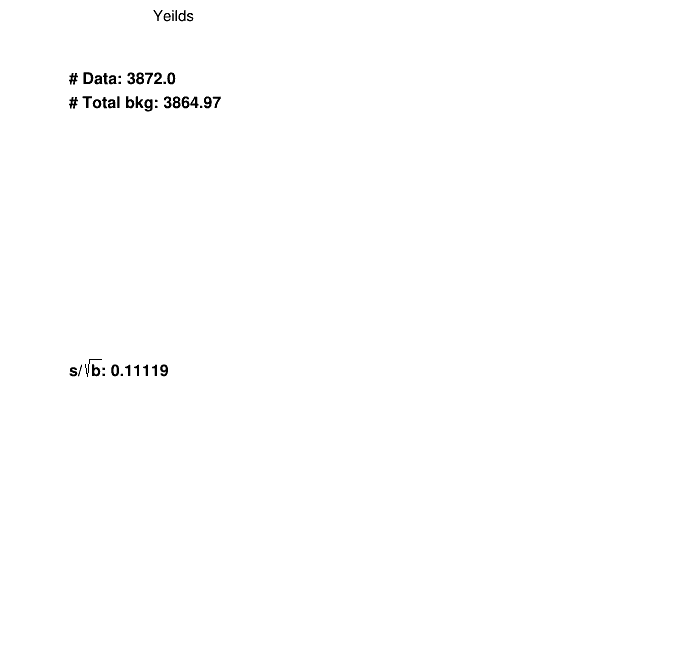

In [30]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 10
DY1500To2000 : 464
DY2000To3000 : 48
DY700To800 : 221
DY800To1000 : 382
Zp-1700_CH-345 : 728
Zp-1700_CH-595 : 532
Zp-1700_CH-845 : 426
Zp-2100_CH-345 : 616
Zp-2100_CH-595 : 502
Zp-2100_CH-845 : 386
Zp-2500_CH-345 : 632
Zp-2500_CH-845 : 354
Zp-2900_CH-1095 : 271
Zp-2900_CH-1345 : 226
Zp-2900_CH-345 : 538
Zp-2900_CH-595 : 461
Zp-2900_CH-845 : 355
Zp-3300_CH-1095 : 260
Zp-3300_CH-1345 : 199
Zp-3300_CH-1595 : 208
Zp-3300_CH-345 : 496
Zp-3300_CH-595 : 399
Zp-3700_CH-1095 : 291
Zp-3700_CH-1345 : 206
Zp-3700_CH-1595 : 161
Zp-3700_CH-1845 : 154
Zp-3700_CH-345 : 496
Zp-3700_CH-595 : 374
Zp-3700_CH-845 : 325
Zp-4100_CH-1095 : 240
Zp-4100_CH-1345 : 199
Zp-4100_CH-1595 : 187
Zp-4100_CH-1845 : 142
Zp-4100_CH-345 : 422
Zp-4100_CH-595 : 376
Zp-4100_CH-845 : 315
TT : 49113
TTSemi : 66
TTZ : 2323
DY : 285
top : 355
antitop : 304

       5.95429727e-04, 2.67859994e-02])}
here {'puweightUp': array([3.97897328e+00, 2.32248312e+00, 4.91848191e+00, 3.36953087e+00,
       1.41770649e+00, 3.60783849e-02, 5.21882993e-01, 2.56614127e+00,
       6.40387688e-04, 3.61743393e-06, 8.10205345e-03, 2.10587917e-01,
       5.37935493e-03, 5.74882021e-05, 1.70128987e-04, 6.23993457e-03,
       2.89198387e-05, 1.42895660e-04, 1.69658208e-05, 3.42006737e-04,
       2.03521307e-04, 9.54276804e-03, 8.72489009e-05, 1.94840710e-03,
       3.07394885e-04, 2.78360778e-07, 3.41876080e-06, 4.09313240e-05,
       1.67879441e-07, 7.58642795e-04]), 'puweightDown': array([1.15775901e-01, 3.94986044e+00, 1.25161904e+01, 5.95685060e+00,
       1.78114832e+00, 6.30670543e-02, 4.31846551e-01, 2.70899411e+00,
       1.53358555e-02, 1.62998895e-03, 8.08997160e-03, 2.11875956e-01,
       7.63453096e-03, 1.18352324e-04, 8.27679714e-05, 4.58942278e-03,
       2.32438906e-05, 1.97717340e-04, 1.60685473e-05, 4.82794724e-04,
       2.09909233e-04, 9.86881

       3.39674066e-03, 1.77002636e-02, 9.61524319e-02])}
here {'puweightUp': array([9.52240092e-01, 5.69943389e+00, 8.32244668e+00, 1.09145556e+00,
       2.54202309e+00, 1.76279082e-03, 7.25446340e-01, 5.05036714e-01,
       5.35094246e-02, 1.29232334e+00, 7.77627313e-01, 1.52021875e-02,
       1.00579880e-01, 4.26190984e-01, 2.41863874e-04, 5.36067384e-04,
       9.85035145e-04, 2.75567400e-02, 1.08696755e-03, 0.00000000e+00,
       2.64982114e-04, 3.04980287e-05, 0.00000000e+00, 8.96825435e-05,
       3.18716126e-05, 9.08518114e-05, 1.83072213e-03, 6.07441639e-07,
       1.56702548e-05, 2.93130171e-04, 7.09849371e-04]), 'puweightDown': array([1.66420407e-01, 9.88150852e+00, 1.45464661e+01, 2.25913011e+00,
       4.95007145e-01, 2.55321580e-02, 1.09200461e+00, 5.22412135e-01,
       4.58449050e-02, 1.43912151e+00, 7.40737624e-01, 2.78750984e-02,
       1.05443333e-01, 4.07488037e-01, 6.69571295e-04, 0.00000000e+00,
       2.00724139e-03, 2.93532340e-02, 1.03562066e-03, 1.06586462e-04

        0.        , 19.30365924, 19.58081571, 42.16476349, 14.82211213])}
here {'puweightUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  3.32052791,  0.54088821,  0.34734343, 20.46092051]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  3.11632765,  0.32122144,  1.42035999, 27.13680806]), 'l1prefiringUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , 10.24868745,  7.88515926,  3.70132155,  4.50134486]), 'l1

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_p

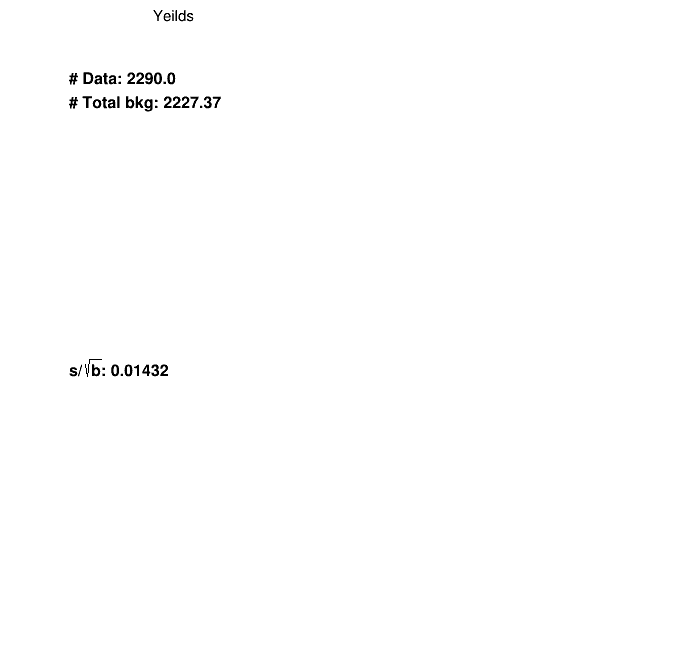

In [31]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
        dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
        dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
    nested_dic_df["scale_u"]=dic_df_scale_u_tmp
    nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [ ]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [32]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
        dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
        dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
    nested_dic_df["scale_u"]=dic_df_scale_u_tmp
    nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
        "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
        "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)  

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 1
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 13
Zp-1700_CH-595 : 213
Zp-1700_CH-845 : 563
Zp-2100_CH-345 : 2
Zp-2100_CH-595 : 85
Zp-2100_CH-845 : 309
Zp-2500_CH-345 : 0
Zp-2500_CH-845 : 162
Zp-2900_CH-1095 : 178
Zp-2900_CH-1345 : 283
Zp-2900_CH-345 : 6
Zp-2900_CH-595 : 22
Zp-2900_CH-845 : 97
Zp-3300_CH-1095 : 131
Zp-3300_CH-1345 : 170
Zp-3300_CH-1595 : 198
Zp-3300_CH-345 : 3
Zp-3300_CH-595 : 11
Zp-3700_CH-1095 : 76
Zp-3700_CH-1345 : 105
Zp-3700_CH-1595 : 153
Zp-3700_CH-1845 : 192
Zp-3700_CH-345 : 4
Zp-3700_CH-595 : 5
Zp-3700_CH-845 : 36
Zp-4100_CH-1095 : 63
Zp-4100_CH-1345 : 87
Zp-4100_CH-1595 : 103
Zp-4100_CH-1845 : 140
Zp-4100_CH-345 : 2
Zp-4100_CH-595 : 2
Zp-4100_CH-845 : 24
TT : 23357
TTSemi : 51
TTZ : 19062
DY : 648
top : 26
antitop : 31
ZZ : 64428
WZ : 17131
WW : 213
Dat

       1.73216768, 0.98186953, 0.        , 0.        , 0.        ])}
{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.80202812e+00,
       3.38784106e-01, 2.19802583e+00, 1.80453278e-03, 1.13774061e-01,
       5.13802511e+00, 1.34589399e+01, 1.79029585e+00, 1.33247808e-02,
       6.74093700e+01, 1.02273815e+00, 0.00000000e+00, 5.70101574e+00,
       1.58121697e-02, 8.10280158e-01, 8.38519051e+00, 0.00000000e+00,
       5.55252867e+00, 2.27255246e+00, 1.76825767e+00, 9.78842566e+00,
       1.49524916e-01, 4.36192138e+00, 2.91573972e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.71252074e+00,
       8.71025434e-01, 1.83895726e+00, 6.54581478e-03, 9.23099977e-02,
       3.30868702e+00, 5.29802247e-03, 2.20065397e+00, 4.80616259e-01,
       1.55397233e+01, 5.82873454e-01, 2.66643589e-01, 5.20768719e+00,
       3.76552855e-02, 5.07387968e-01, 7.94690047e+00, 1.80340447e+01,
       

       1.42801262, 2.01309162, 0.        , 0.        , 0.        ])}
{'puweightUp': array([2.16622588e+01, 2.40961872e+02, 4.24372558e-02, 8.96849808e-03,
       7.99839806e-02, 1.71690657e-01, 5.27484624e-02, 1.85178838e-02,
       3.63866963e-02, 2.84432003e-03, 3.60525623e-03, 6.63815532e-02,
       8.26201767e-03, 7.99164011e-04, 6.58948265e-02, 1.83185248e-05,
       9.59330535e-04, 1.03167612e-05, 1.63638316e-03, 1.09374969e-04,
       6.39535232e-04, 6.06456229e-04, 2.02105336e-04, 8.16626390e-03,
       1.88091328e-03, 1.54033658e-04, 1.61225476e-05, 4.29431976e-07]), 'puweightDown': array([1.37856093e+02, 4.52018669e+01, 3.63829472e-02, 9.04830131e-02,
       2.05014952e-01, 2.11481137e-01, 6.98227659e-02, 9.69290583e-02,
       2.59470801e-02, 2.80284125e-02, 4.99197182e-03, 6.77460983e-02,
       6.96125513e-03, 0.00000000e+00, 1.22675361e-02, 9.24832090e-05,
       8.29989540e-04, 1.46980314e-04, 1.83012478e-03, 2.96259173e-04,
       2.27579291e-03, 4.64145252e-04, 3.81109

       9.58668330e-02, 1.68297765e-02, 3.58891840e-02, 4.67150543e-02])}
{'puweightUp': array([449.33345933]), 'puweightDown': array([396.56492334]), 'l1prefiringUp': array([31.30208605]), 'l1prefiringDown': array([32.57580734]), 'effSFUp': array([925.95290797]), 'effSFDown': array([883.9353963]), 'topSFUp': array([9.61860916]), 'topSFDown': array([0.]), 'trigSFUp': array([14.2042857]), 'trigSFDown': array([17.27993909]), 'metUp': array([3227.92097919]), 'metDown': array([476.54853931]), 'sum_up': array([68.25197673]), 'sum_down': array([42.50770054])}
{'puweightUp': array([2.56601664e+01, 1.96795174e+01, 5.14531869e+00, 3.64630509e+00,
       6.91934501e-01, 1.07549986e-01, 7.80227619e+00, 2.20244054e+01,
       1.86389128e+00, 2.76927318e-01, 8.57024312e+00, 1.62931135e-01,
       1.08673880e-02, 1.39830887e+00, 5.52395937e-02, 7.72891200e-02,
       4.98121736e-01, 4.31537640e-05, 5.42830845e-03, 1.67146383e-01,
       4.42517719e-03, 2.07410633e-01, 5.67994263e-02, 5.31479366e-01,


       1.80557758e-02, 1.80116755e-02, 1.52399779e-01])}
here here {'puweightUp': array([449.33345933]), 'puweightDown': array([396.56492334]), 'l1prefiringUp': array([31.30208605]), 'l1prefiringDown': array([32.57580734]), 'effSFUp': array([925.95290797]), 'effSFDown': array([883.9353963]), 'topSFUp': array([9.61860916]), 'topSFDown': array([0.]), 'trigSFUp': array([14.2042857]), 'trigSFDown': array([17.27993909]), 'metUp': array([3227.92097919]), 'metDown': array([476.54853931]), 'sum_up': array([68.25197673]), 'sum_down': array([42.50770054])}
{'puweightUp': array([2.56601664e+01, 1.96795174e+01, 5.14531869e+00, 3.64630509e+00,
       6.91934501e-01, 1.07549986e-01, 7.80227619e+00, 2.20244054e+01,
       1.86389128e+00, 2.76927318e-01, 8.57024312e+00, 1.62931135e-01,
       1.08673880e-02, 1.39830887e+00, 5.52395937e-02, 7.72891200e-02,
       4.98121736e-01, 4.31537640e-05, 5.42830845e-03, 1.67146383e-01,
       4.42517719e-03, 2.07410633e-01, 5.67994263e-02, 5.31479366e-01,
      

       1.80557758e-02, 1.80116755e-02, 1.52399779e-01])}
{'puweightUp': array([1.05100654e+02, 1.67299496e+02, 1.71708764e+00, 1.88637036e+01,
       4.37845485e-02, 9.64506024e+00, 2.45840327e+00, 8.87438654e-01,
       1.97543860e-02, 6.09256543e-01, 8.02566871e-02, 3.12215639e-03,
       6.74763628e-03, 3.64199945e-02, 4.02905230e-06, 4.62275743e-05,
       5.34000447e-05, 9.27584052e-05, 5.98227135e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 5.88302517e-09, 0.00000000e+00,
       0.00000000e+00, 7.51588179e-09, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([9.01072835e+01, 8.53165279e+01, 0.00000000e+00, 1.02487596e+02,
       2.78798643e-02, 4.81686882e+00, 2.78070210e+00, 7.73847062e-01,
       2.53708938e-02, 6.20902565e-01, 8.72140492e-02, 7.25035884e-03,
       2.42895087e-02, 5.69715719e-02, 2.64783674e-03, 1.58117440e-05,
       4.24742779e-05, 8.25967847e-05, 1.29920976e-05, 0.00000000e+00,
       0.00000000e+

       0.00000000e+00, 0.00000000e+00])}


KeyError: 'phi_lead_pre'

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230416_16pre/Presel/ee16pre/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has 

In [ ]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

In [ ]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
        dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
        dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
    nested_dic_df["scale_u"]=dic_df_scale_u_tmp
    nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [ ]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [ ]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [ ]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

In [ ]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")